In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path("..").resolve()
sys.path.append(str(ROOT_DIR))

import numpy as np
import spectral
import matplotlib.pyplot as plt

from src.rois import selecionar_rois

In [2]:
ROOT_DIR = Path("..").resolve()

PATH_CUBOS = (
    ROOT_DIR
    / "data"
    / "silver level"
    / "bandas_removidas"
)

bandas_rgb_originais = (135, 85, 35)
bandas_remover_inicio = 15

bandas_rgb_ajustadas = (
    bandas_rgb_originais[0] - bandas_remover_inicio,
    bandas_rgb_originais[1] - bandas_remover_inicio,
    bandas_rgb_originais[2] - bandas_remover_inicio,
)

hough_param2 = 1

In [3]:
paths = sorted(PATH_CUBOS.glob("*.npy"))
len(paths)

19

In [4]:
def plot_roi(img, title):
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

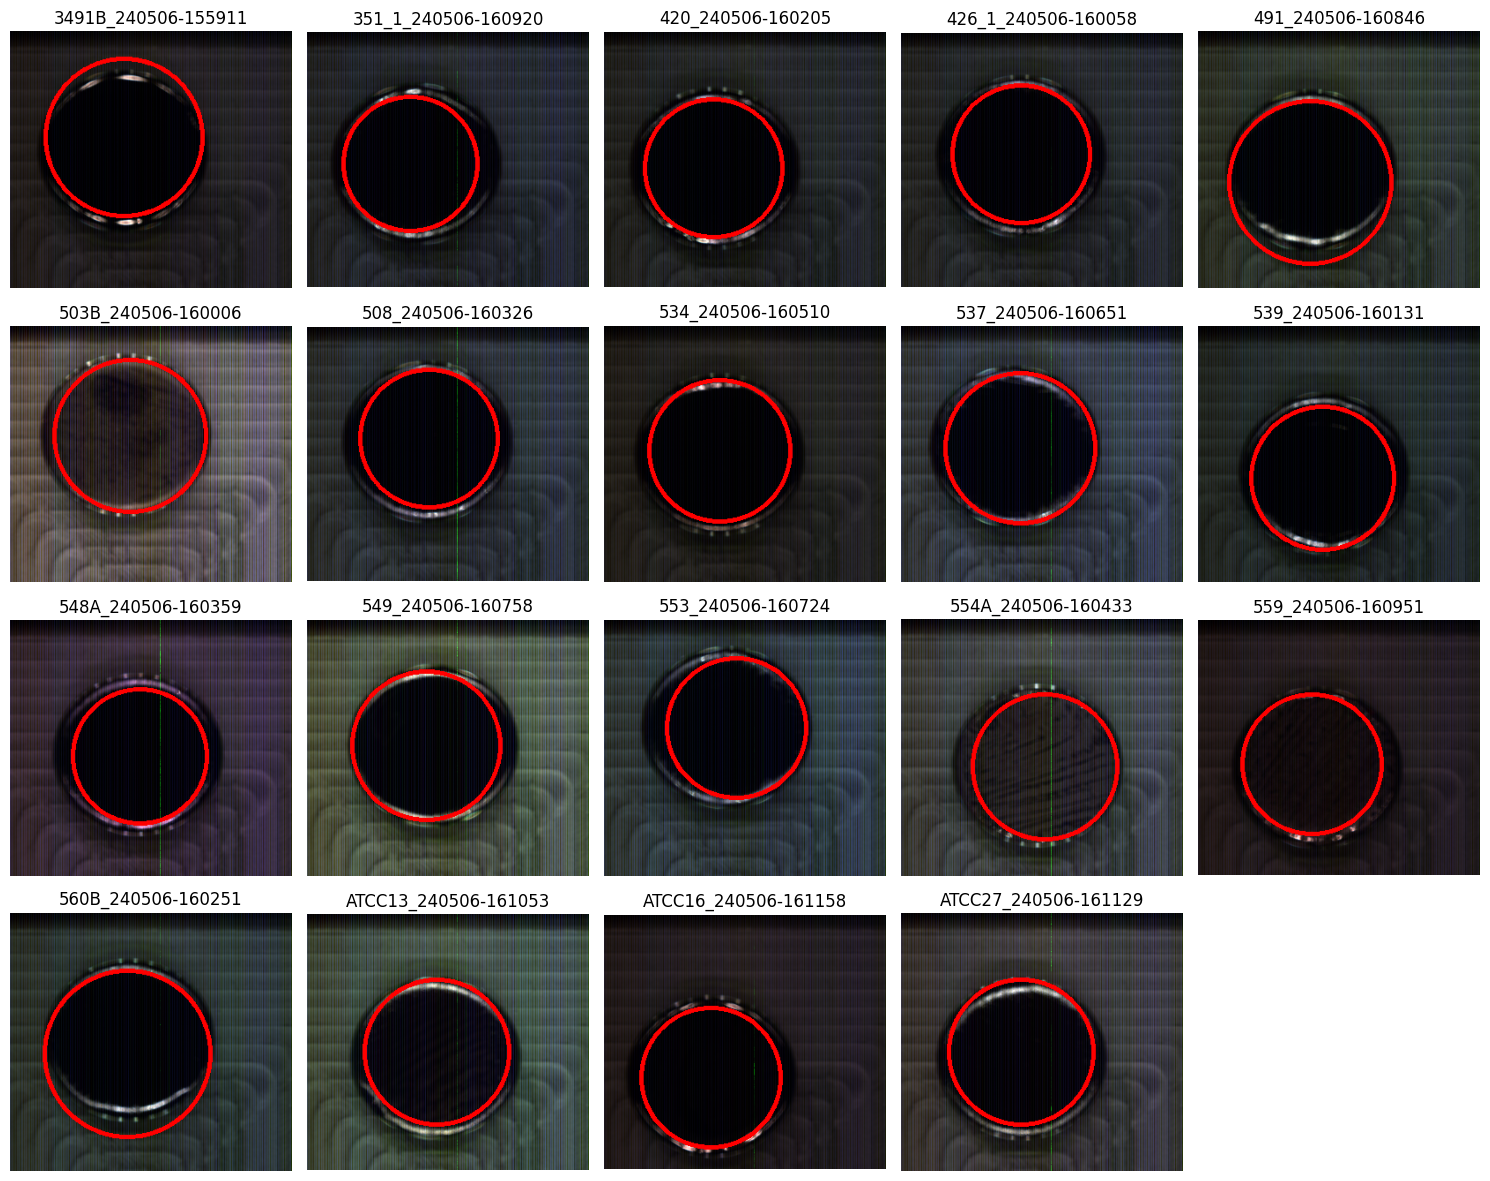

In [5]:
n_samples = len(paths)
n_cols = 5
n_rows = int(np.ceil(n_samples / n_cols))

plt.figure(figsize=(15, 3 * n_rows))

for i, path in enumerate(paths):
    cube = np.load(path)

    # selecionar_rois retorna (roi, rgb_com_circulo, coords, mask) na versão atual
    roi, rgb_com_roi, _, _ = selecionar_rois(
        cube,
        bandas=bandas_rgb_ajustadas,
        param2_ajustado=hough_param2
    )

    plt.subplot(n_rows, n_cols, i + 1)
    plot_roi(rgb_com_roi, path.stem)

plt.tight_layout()
plt.show()

19 cubos disponíveis:
  [0] 3491B_240506-155911
  [1] 351_1_240506-160920
  [2] 420_240506-160205
  [3] 426_1_240506-160058
  [4] 491_240506-160846
  [5] 503B_240506-160006
  [6] 508_240506-160326
  [7] 534_240506-160510
  [8] 537_240506-160651
  [9] 539_240506-160131
  [10] 548A_240506-160359
  [11] 549_240506-160758
  [12] 553_240506-160724
  [13] 554A_240506-160433
  [14] 559_240506-160951
  [15] 560B_240506-160251
  [16] ATCC13_240506-161053
  [17] ATCC16_240506-161158
  [18] ATCC27_240506-161129

Testando: 3491B_240506-155911


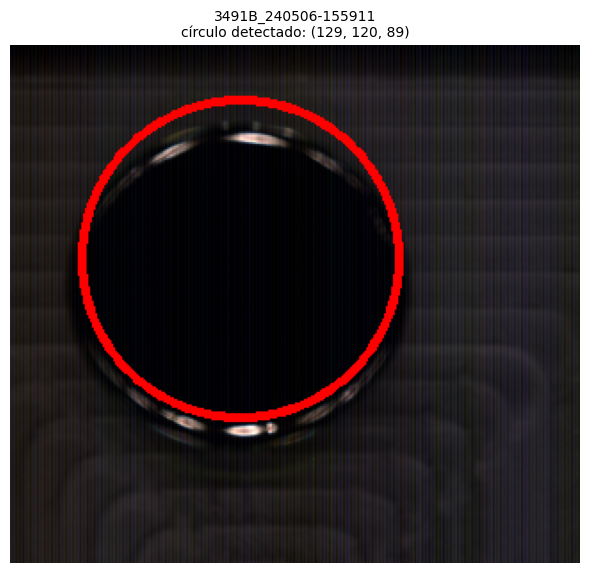

In [6]:
# ── Diagnóstico individual — inspeciona uma placa específica em detalhe ───────
# Nota: src/rois.py atual usa parâmetros fixos (GaussianBlur 7×7, dp=1.2,
# raio×0.95) — não é mais possível variar blur/dp por chamada como antes.
# Esta célula apenas amplia a visualização de uma amostra específica.

if not paths:
    print("ERRO: 'paths' está vazio.")
    print(f"Verifique se PATH_CUBOS existe e contém arquivos .npy: {PATH_CUBOS}")
else:
    print(f"{len(paths)} cubos disponíveis:")
    for i, p in enumerate(paths):
        print(f"  [{i}] {p.stem}")

    IDX_AMOSTRA = 0   # ← altere para o índice da placa a inspecionar

    cube_teste = np.load(paths[IDX_AMOSTRA])
    print(f"\nTestando: {paths[IDX_AMOSTRA].stem}")

    roi, rgb_vis, coords, mask = selecionar_rois(
        cube_teste, bandas=bandas_rgb_ajustadas, param2_ajustado=hough_param2
    )

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(rgb_vis if rgb_vis is not None else np.zeros((100, 100, 3), dtype=np.uint8))
    ax.set_title(f"{paths[IDX_AMOSTRA].stem}\ncírculo detectado: {coords}", fontsize=10)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

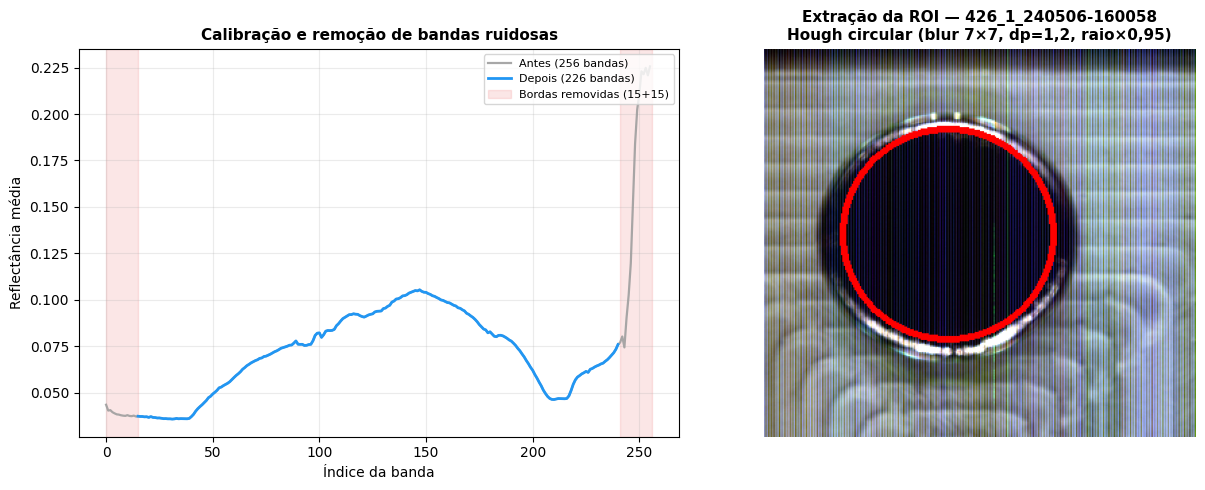

Figura salva: D:\IC PUC\HSI-Pipeline-Automation\runs\426_1_240506-160058\figuras\calibracao_e_roi.png
Círculo detectado: centro=(136, 137), raio=78px


In [7]:
# ── Figura para o relatório: calibração/remoção de bandas + extração de ROI ──
# Painel esquerdo: espectro médio antes x depois da remoção das 15 bandas de
# borda (mesma amostra usada nas demais figuras do relatório, para consistência).
# Painel direito: imagem RGB falso-cor com o círculo detectado pela Transformada
# de Hough e a máscara de ROI aplicada (parâmetros reais do pipeline: blur 7×7,
# dp=1,2, raio×0,95).

SAMPLE_ID = "426_1_240506-160058"   # mesma amostra usada em NB04/NB06 (1ª por ordem)
OUTPUT_DIR = ROOT_DIR / "runs" / "426_1_240506-160058" / "figuras"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

path_calibrado = ROOT_DIR / "data" / "silver level" / "hsi_calibrado" / f"{SAMPLE_ID}.npy"
path_cortado    = ROOT_DIR / "data" / "silver level" / "bandas_removidas" / f"{SAMPLE_ID}.npy"

cubo_calibrado = np.load(path_calibrado)
cubo_cortado   = np.load(path_cortado)

mean_antes  = cubo_calibrado.mean(axis=(0, 1))
mean_depois = cubo_cortado.mean(axis=(0, 1))
n_bandas_orig = len(mean_antes)
bandas_remover_inicio_fig = 15
bandas_remover_fim_fig = 15

# ROI: usa o cubo já com bandas removidas, mesmo input do pipeline real
roi_img, rgb_com_circulo, coords_roi, mask_roi = selecionar_rois(
    cubo_cortado, bandas=bandas_rgb_ajustadas, param2_ajustado=hough_param2
)

# selecionar_rois() não normaliza o contraste antes de converter para 0-255
# (comportamento de src/rois.py, inalterado — não afeta a ROI nem os pixels
# usados a jusante, só deixa a pré-visualização escura). Para exibição nesta
# figura, aplica-se um alongamento de contraste por percentil (2–98%),
# preservando o círculo vermelho já desenhado.
rgb_float = rgb_com_circulo.astype(float)
is_circulo = (rgb_float[..., 0] > 200) & (rgb_float[..., 1] < 60) & (rgb_float[..., 2] < 60)
amostra_cores = rgb_float[~is_circulo]
p2, p98 = np.percentile(amostra_cores, (2, 98))
rgb_realcado = np.clip((rgb_float - p2) / (p98 - p2 + 1e-6), 0, 1)
rgb_realcado[is_circulo] = [1.0, 0.0, 0.0]  # mantém o círculo vermelho puro

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Painel A — espectro antes/depois da remoção de bandas
ax = axes[0]
ax.plot(range(n_bandas_orig), mean_antes, color="#9E9E9E", linewidth=1.6,
        alpha=0.9, label="Antes (256 bandas)")
ax.plot(range(bandas_remover_inicio_fig, n_bandas_orig - bandas_remover_fim_fig),
        mean_depois, color="#2196F3", linewidth=2.0, label="Depois (226 bandas)")
ax.axvspan(0, bandas_remover_inicio_fig, color="#E53935", alpha=0.12)
ax.axvspan(n_bandas_orig - bandas_remover_fim_fig, n_bandas_orig, color="#E53935", alpha=0.12,
           label="Bordas removidas (15+15)")
ax.set_xlabel("Índice da banda", fontsize=10)
ax.set_ylabel("Reflectância média", fontsize=10)
ax.set_title("Calibração e remoção de bandas ruidosas", fontsize=11, fontweight="bold")
ax.legend(fontsize=8, loc="upper right")
ax.grid(True, alpha=0.25)

# Painel B — RGB (contraste realçado p/ exibição) com círculo/ROI detectada
ax = axes[1]
ax.imshow(rgb_realcado)
ax.set_title(f"Extração da ROI — {SAMPLE_ID}\nHough circular (blur 7×7, dp=1,2, raio×0,95)",
             fontsize=11, fontweight="bold")
ax.axis("off")

plt.tight_layout()
caminho_fig = OUTPUT_DIR / "calibracao_e_roi.png"
plt.savefig(caminho_fig, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva: {caminho_fig}")
print(f"Círculo detectado: centro={coords_roi[:2]}, raio={coords_roi[2]}px")